# Numerical Methods for First-Order ODEs

This chapter is about computing solutions of the **initial value problem** (IVP)

$$y' = f(x, y), \qquad y(x_0) = y_0, \qquad x_0 \le x \le b$$

when no formula for $y(x)$ is available. It starts from the simplest method (Euler) and builds up to the ideas used inside professional solvers: higher-order Runge–Kutta methods, error estimation, stability, stiffness, adaptive step size and multistep methods.

Prerequisite: [First-Order Differential Equations](../first-order-differential-equations.ipynb), sections 1–5.

## Chapter contents

| | Section | What it covers |
|---|---|---|
| 1 | [Euler's method](01-eulers-method.ipynb) | Three derivations, local and global error, a proof that Euler converges, examples where it fails |
| 2 | [Second-order Runge–Kutta methods](02-second-order-runge-kutta.ipynb) | Heun, midpoint and Ralston; deriving the whole two-stage family from the Taylor series |
| 3 | [The classical Runge–Kutta method (RK4)](03-runge-kutta-4.ipynb) | RK4, Butcher tableaux, order conditions, the Butcher barriers |
| 4 | [Error, order and efficiency](04-error-order-efficiency.ipynb) | Measuring order, accuracy per unit of work, Richardson extrapolation, round-off error |
| 5 | [Stability and stiff equations](05-stability-and-stiffness.ipynb) | Amplification factors, stability regions, implicit methods, A- and L-stability, stiffness |
| 6 | [Adaptive step size](06-adaptive-step-size.ipynb) | Error estimators, embedded pairs (Heun–Euler, Bogacki–Shampine), step-size control |
| 7 | [Multistep methods](07-multistep-methods.ipynb) | Adams–Bashforth, Adams–Moulton, predictor–corrector, zero-stability and Dahlquist's theorems |
| 8 | [Systems and higher-order equations](08-systems-and-higher-order.ipynb) | Vector ODEs, oscillators, the pendulum, predator–prey models, conserved quantities |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

## 1. Why numerical methods?

The analytical methods (separable, linear, exact equations) cover only a small fraction of the equations that occur in practice. Even an innocent-looking equation such as the Riccati equation

$$y' = x^2 + y^2$$

has no solution in terms of elementary functions. Other times a formula exists but is implicit, or contains integrals nobody can evaluate. A numerical method only needs to be able to **evaluate** $f(x, y)$ at given numbers, so it works for every equation.

The price is that the result is a table of approximate values, not a formula, and it contains **errors**. Most of this chapter is about understanding, estimating and controlling those errors.

## 2. When does the problem have a solution?

Before computing a solution it is worth knowing that there is exactly one solution to compute.

**Lipschitz condition.** $f$ satisfies a Lipschitz condition in $y$ on a region $D$ if there is a constant $L$ such that

$$|f(x, y_1) - f(x, y_2)| \le L\,|y_1 - y_2| \qquad \text{for all } (x, y_1), (x, y_2) \in D.$$

If $\partial f/\partial y$ exists and is bounded on $D$ (and $D$ is convex in $y$), the mean value theorem shows that $L = \max_D |\partial f / \partial y|$ works.

**Theorem (Picard–Lindelöf).** If $f$ is continuous and satisfies a Lipschitz condition in $y$ on a rectangle around $(x_0, y_0)$, then the IVP has **exactly one** solution on some interval around $x_0$.

| Equation | $\partial f/\partial y$ | What happens |
|---|---|---|
| $y' = x + y$ | $1$ | $L = 1$ everywhere: one solution, defined for all $x$ |
| $y' = y^2$, $y(0) = 1$ | $2y$ | Lipschitz only on bounded $y$-ranges: the solution $y = 1/(1-x)$ exists only for $x < 1$ (it blows up) |
| $y' = \sqrt{|y|}$, $y(0) = 0$ | $\tfrac{1}{2}|y|^{-1/2}$, unbounded at $y = 0$ | **Not** Lipschitz: both $y = 0$ and $y = x^2/4$ ($x \ge 0$) are solutions |

The last two rows are warnings. A numerical method applied to $y' = y^2$ happily produces finite numbers beyond $x = 1$, and applied to $y' = \sqrt{|y|}$ it returns $y_n = 0$ forever without telling you a second solution exists. **The theory tells you when the numbers can be trusted.**

## 3. How sensitive is the solution to its starting value?

Let $y$ and $z$ solve the same equation with slightly different starting values. Using the Lipschitz condition and Grönwall's inequality one can show

$$|y(x) - z(x)| \le e^{L(x - x_0)}\,|y_0 - z_0|.$$

So a small change in the starting value can grow, at worst, exponentially with rate $L$. Whether it actually grows depends on the **sign** of $\partial f/\partial y$:

* $\partial f/\partial y > 0$: neighbouring solutions **spread apart**;
* $\partial f/\partial y < 0$: neighbouring solutions **draw together**.

This matters for numerical methods because every step makes a small error, which moves the computed solution onto a *neighbouring* solution curve. If neighbouring curves spread apart, those errors are amplified as the computation proceeds; if they draw together, old errors die out.

The plots show solutions starting from $y_0 \in [0.8, 1.2]$ for $y' = x + y$ (solutions $y = Ce^{x} - x - 1$) and $y' = x - y$ (solutions $y = x - 1 + Ce^{-x}$).

y0 = 0.8:  y(3) =  32.1540 for x + y,   2.0896 for x − y
y0 = 1.2:  y(3) =  40.1882 for x + y,   2.1095 for x − y


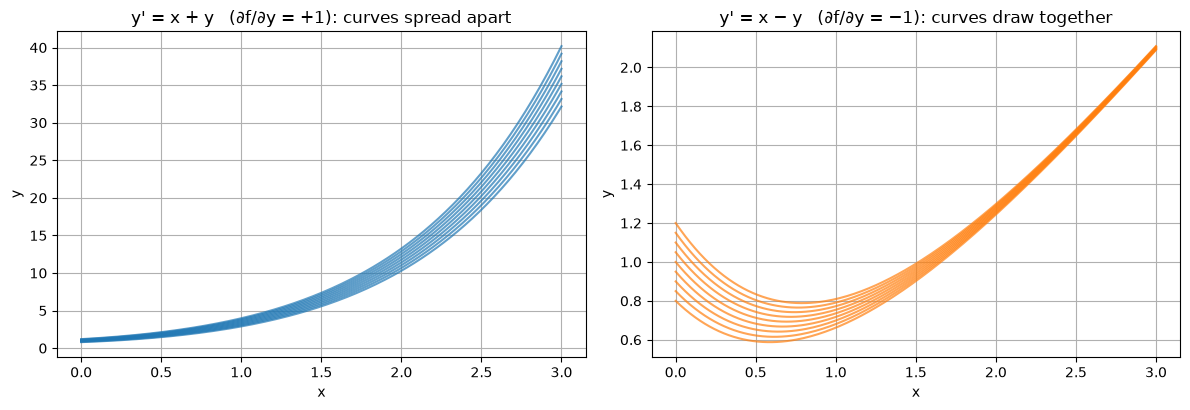

In [2]:
x = np.linspace(0, 3, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for y0 in np.linspace(0.8, 1.2, 9):
    C = y0 + 1
    axes[0].plot(x, C * np.exp(x) - x - 1, color="C0", alpha=0.7)
    axes[1].plot(x, x - 1 + C * np.exp(-x), color="C1", alpha=0.7)
axes[0].set_title("y' = x + y   (∂f/∂y = +1): curves spread apart")
axes[1].set_title("y' = x − y   (∂f/∂y = −1): curves draw together")
for ax in axes:
    ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout()

for y0 in (0.8, 1.2):
    C = y0 + 1
    print(f"y0 = {y0}:  y(3) = {C*np.exp(3) - 4:8.4f} for x + y,   {2 + C*np.exp(-3):.4f} for x − y")

A spread of $0.4$ in the starting value becomes a spread of $0.4e^3 \approx 8$ at $x = 3$ for the first equation, but shrinks to $0.4e^{-3} \approx 0.02$ for the second.

## 4. Discretising the problem

A numerical method replaces the unknown function by its values on a grid.

| Symbol | Meaning |
|---|---|
| $h$ | step size |
| $x_n = x_0 + nh$ | grid points, $n = 0, 1, \dots, N$ with $N = (b - x_0)/h$ |
| $y(x_n)$ | the **exact** solution at $x_n$ (unknown) |
| $y_n$ | the **computed** approximation to $y(x_n)$ |
| $f_n = f(x_n, y_n)$ | the slope evaluated at the computed point |
| $e_n = y(x_n) - y_n$ | the global error at $x_n$ |

## 5. Every method approximates an integral

Integrating $y' = f(x, y)$ over one step gives the **exact** relation

$$y(x_{n+1}) = y(x_n) + \int_{x_n}^{x_{n+1}} f\big(x, y(x)\big)\,dx.$$

The integral cannot be computed exactly because $y(x)$ inside it is unknown. Each method is a different way of approximating it, and most correspond to a familiar quadrature rule:

| Method | Approximates the integral by | Quadrature rule | Section |
|---|---|---|---|
| Euler | slope at the left end | left rectangle | 1 |
| Backward Euler | slope at the right end | right rectangle | 5 |
| Midpoint | slope at the middle | midpoint rule | 2 |
| Heun, trapezoidal | average of the end slopes | trapezoidal rule | 2, 5 |
| RK4 | weighted average of four slopes | Simpson's rule | 3 |
| Adams methods | integral of a polynomial through earlier slopes | interpolatory quadrature | 7 |

## 6. Classifying methods

* **One-step or multistep.** A one-step method (Euler, Runge–Kutta) computes $y_{n+1}$ from $(x_n, y_n)$ only. A multistep method also reuses $y_{n-1}, y_{n-2}, \dots$ and their slopes.
* **Explicit or implicit.** An explicit method gives $y_{n+1}$ by a formula. An implicit method gives an *equation* for $y_{n+1}$ that has to be solved at every step. Implicit methods cost more per step but can be far more stable.
* **Fixed or adaptive step.** A fixed-step method uses the same $h$ throughout. An adaptive method estimates its own error and changes $h$ as it goes.

## 7. Three properties every method needs

* **Consistency.** The formula is a correct approximation of the ODE: the error made in a single step, divided by $h$, tends to $0$ as $h \to 0$.
* **Stability.** Errors made in early steps are not amplified without bound by later steps.
* **Convergence.** The computed values approach the exact solution as the step shrinks: $\max_n |y(x_n) - y_n| \to 0$ as $h \to 0$.

The central theorem of the subject says, roughly,

$$\textbf{consistency} + \textbf{stability} \;\Longrightarrow\; \textbf{convergence}.$$

A convergent method has **order $p$** if its global error behaves like $Ch^p$. Sections 1–4 are mostly about consistency and order, Sections 5 and 7 about stability.

## 8. The test problem

To be able to measure errors exactly, most sections use the same test problem:

$$y' = x + y, \qquad y(0) = 1, \qquad \text{exact solution } y = 2e^{x} - x - 1.$$